In [1]:
from WF4Py import waveforms as WF;
from WF4Py import WFutils as utils;

import numpy as np
from astropy.cosmology import Planck18

import pycbc.conversions as cvs;
import pycbc.waveform as pycbc_wf;
import pycbc.types as pycbc_tps;

import time
import sys
import os

import matplotlib.pyplot as plt
from matplotlib import gridspec
from matplotlib import rc
rc('text', usetex=False)


ourcodenameString = 'WF4Py'

/workspace/minconda3/envs/preload/lib/python3.9/site-packages/pycbc/types/array.py:36: UserWarning: Wswiglal-redir-stdio:

SWIGLAL standard output/error redirection is enabled in IPython.
This may lead to performance penalties. To disable locally, use:

with lal.no_swig_redirect_standard_output_error():
    ...

To disable globally, use:

lal.swig_redirect_standard_output_error(False)

Note however that this will likely lead to error messages from
LAL functions being either misdirected or lost when called from
Jupyter notebooks.

To suppress this warning, use:

import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
import lal

  import lal as _lal
/workspace/minconda3/envs/preload/lib/python3.9/site-packages/pykerr/qnm.py:2: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  im

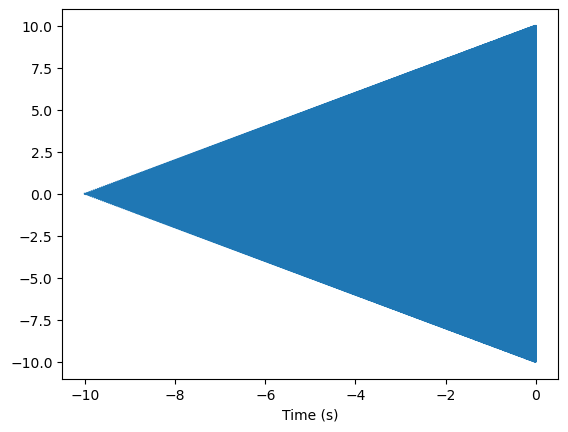

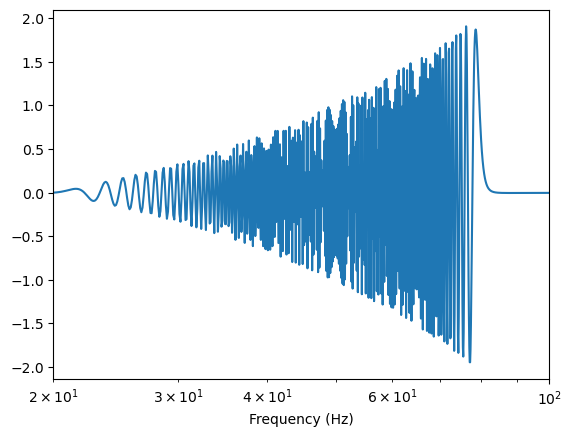

In [2]:
import numpy
import matplotlib.pyplot as pp
import pycbc.waveform
from pycbc.types import TimeSeries


def test_waveform(**args):
    flow = args['f_lower'] # Required parameter
    dt = args['delta_t']   # Required parameter
    fpeak = args['fpeak']  # A new parameter for my model

    t = numpy.arange(0, 10, dt)
    f = t/t.max() * (fpeak - flow) + flow
    a = t

    wf = numpy.exp(2.0j * numpy.pi * f * t) * a

    # Return product should be a pycbc time series in this case for
    # each GW polarization
    #
    #
    # Note that by convention, the time at 0 is a fiducial reference.
    # For CBC waveforms, this would be set to where the merger occurs
    offset = - len(t) * dt
    wf = TimeSeries(wf, delta_t=dt, epoch=offset)
    return wf.real(), wf.imag()


# This tells pycbc about our new waveform so we can call it from standard
# pycbc functions. If this were a frequency-domain model, select 'frequency'
# instead of 'time' to this function call.
pycbc.waveform.add_custom_waveform('test', test_waveform, 'time', force=True)

# Let's plot what our new waveform looks like
hp, hc = pycbc.waveform.get_td_waveform(approximant="test",
                                        f_lower=20, fpeak=50,
                                        delta_t=1.0/4096)
pp.figure(0)
pp.plot(hp.sample_times, hp)
pp.xlabel('Time (s)')

pp.figure(1)
hf = hp.to_frequencyseries()
pp.plot(hf.sample_frequencies, hf.real())
pp.xlabel('Frequency (Hz)')
pp.xscale('log')
pp.xlim(20, 100)
pp.show()

In [ ]:
# WF4Py_waveform_dchi_modified